# Multivariate analysis

Pairwise structure of the numerical variables, then multivariate outlier detection
with Mahalanobis distance.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from scipy.stats import probplot
from sklearn.covariance import EmpiricalCovariance

import helpers
from helpers import NUM_COLS

helpers.setup()

In [2]:
data = helpers.load_data()

## Pairwise relationships

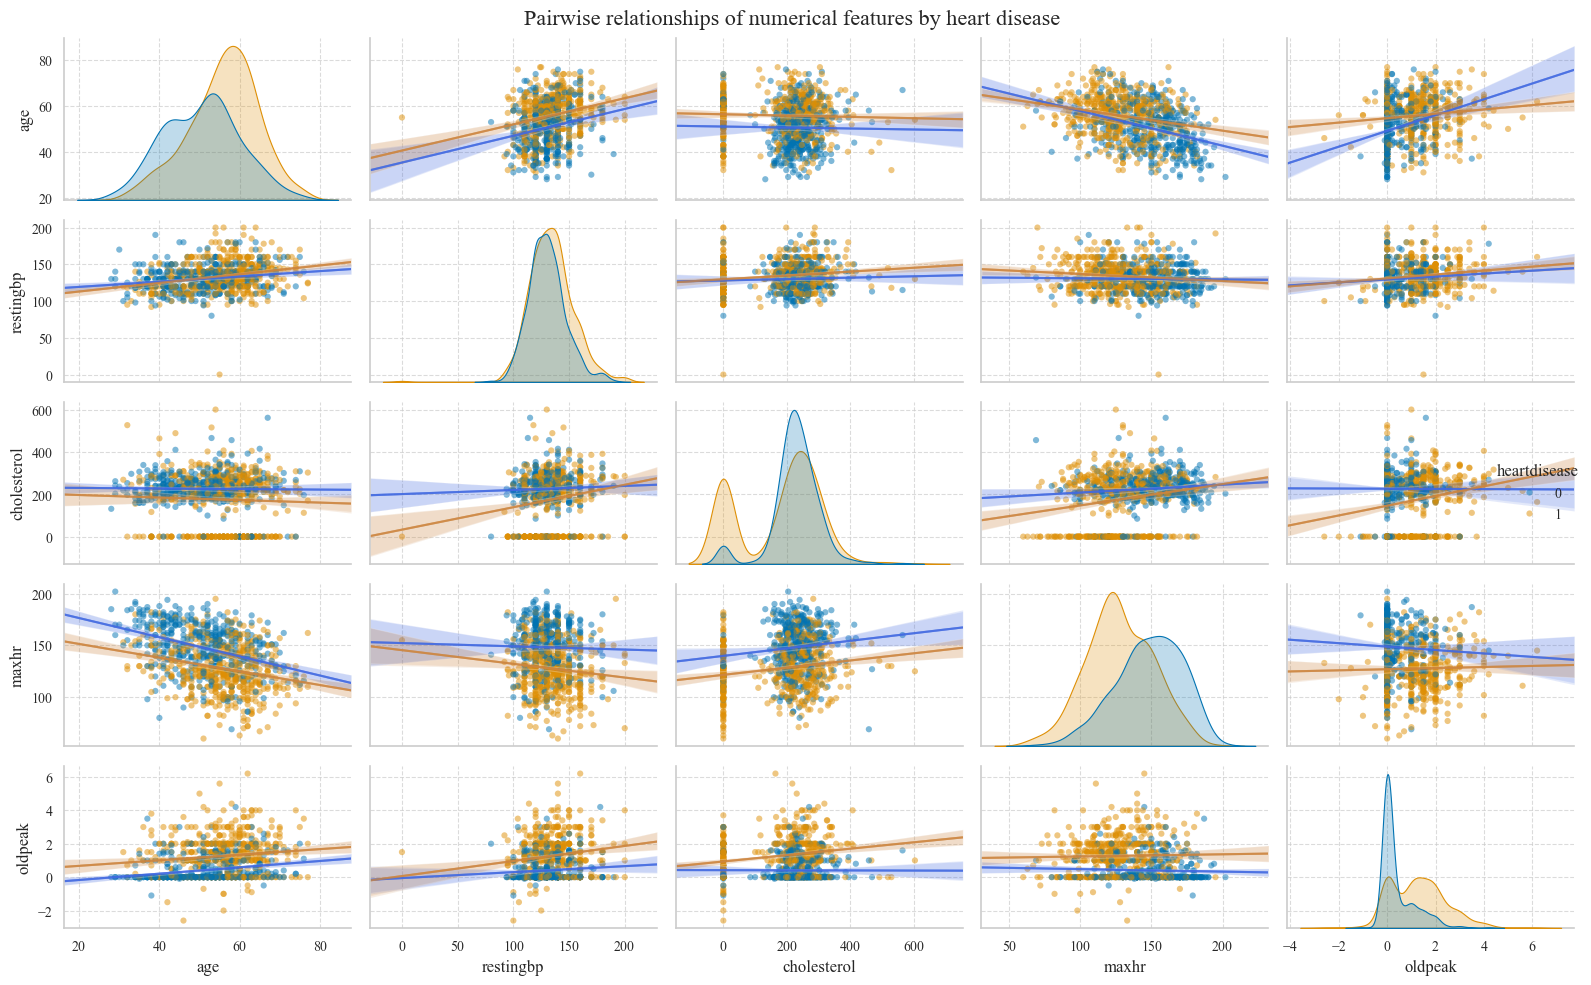

In [3]:
def regression_by_target(x, y, **kwargs):
    """Draw one regression line per heart-disease group, no scatter."""
    df = kwargs.pop('data')
    ax = plt.gca()
    for value, colour in [(0, 'royalblue'), (1, 'peru')]:
        subset = df[df['heartdisease'] == value]
        sns.regplot(x=subset[x.name], y=subset[y.name], scatter=False, ax=ax,
                    color=colour, truncate=False, line_kws={'lw': 1.5, 'alpha': 0.7})


def pairgrid_by_target(df, title):
    grid = sns.pairplot(df, hue='heartdisease', height=2, aspect=1.5,
                        diag_kind='kde', corner=False,
                        plot_kws={'s': 20, 'alpha': 0.5, 'edgecolor': 'none',
                                  'linewidth': 0.3})
    grid.map_lower(regression_by_target, data=df)
    grid.map_upper(regression_by_target, data=df)

    for ax in grid.axes.flat:
        ax.grid(True, which='major', axis='both', linestyle='--', alpha=0.7)

    grid.fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()
    return grid


pairgrid_by_target(data[NUM_COLS + ['heartdisease']],
                   'Pairwise relationships of numerical features by heart disease')

- Resting blood pressure tends to increase by age, no matter having heart disease or not
- Max heart rate skews left in those who have heart disease => low max heart rate may signify an increased risk of heart diseases or other medical condition
  - [What is a normal heart rate?](https://www.health.harvard.edu/heart-health/what-your-heart-rate-is-telling-you)
- People with oldpeak > 0 tends to have heart disease
- High cholesterol + >0 oldpeak tend to have heart disease
- High resting blood pressure + > 0 oldpeak tend to have heart disease

### Same plot with the placeholder zeros treated as missing

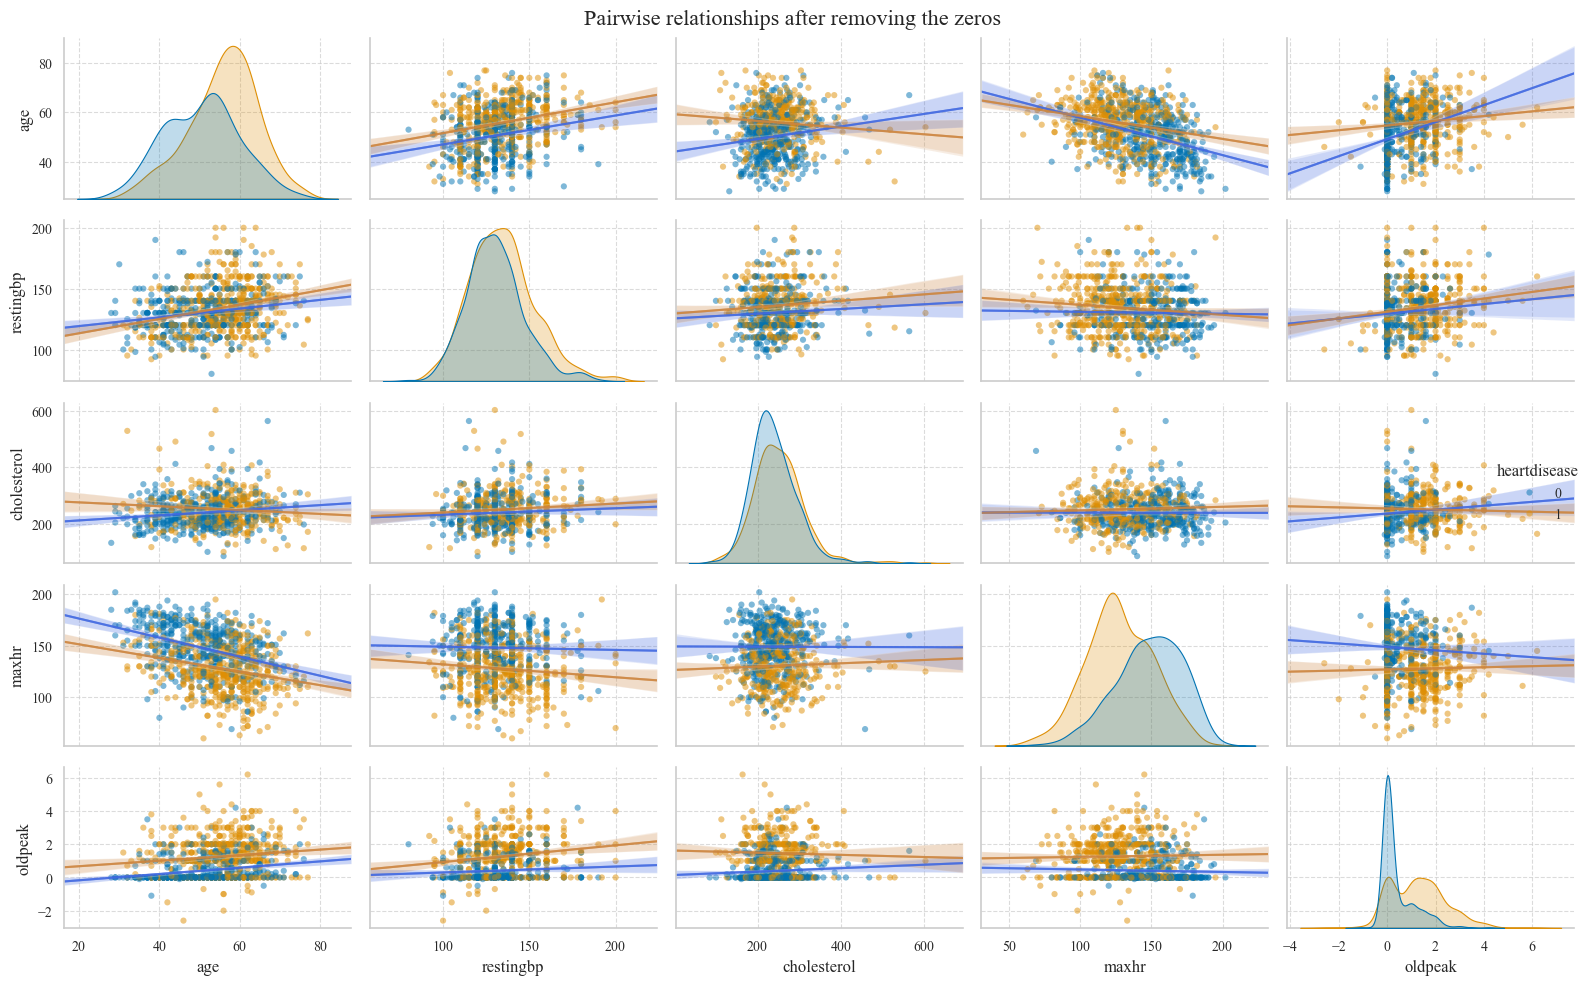

In [4]:
df_clean = helpers.load_data(zeros_as_missing=True)

pairgrid_by_target(df_clean[NUM_COLS + ['heartdisease']],
                   'Pairwise relationships after removing the zeros')

## Age by sex and target

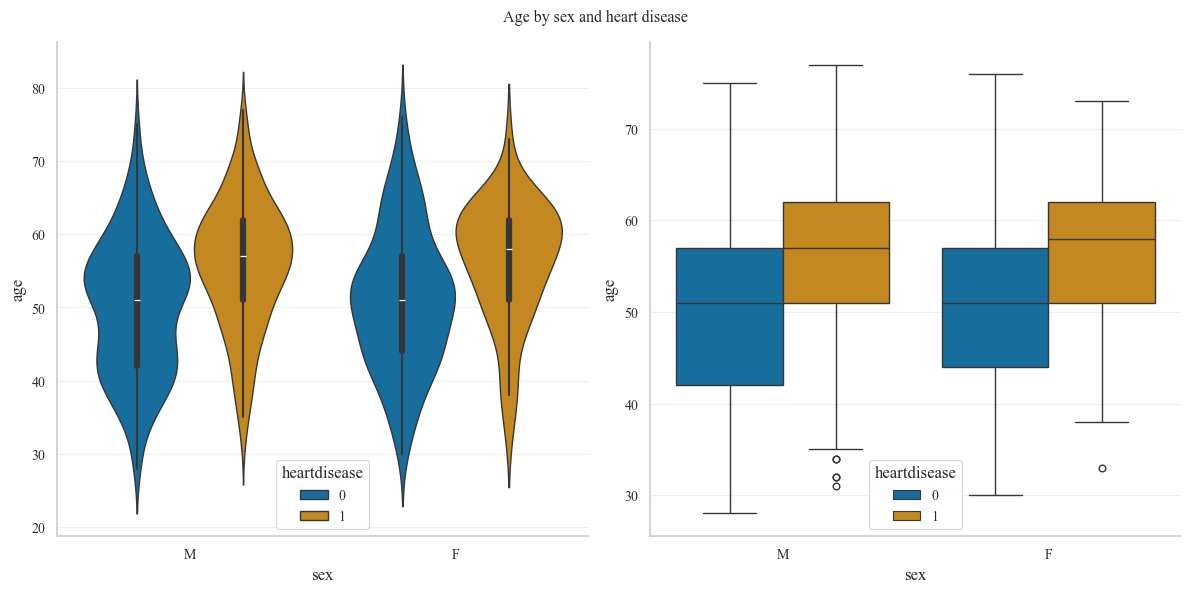

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Age by sex and heart disease')

sns.violinplot(data=data, x='sex', y='age', hue='heartdisease', ax=axes[0])
sns.boxplot(data=data, x='sex', y='age', hue='heartdisease', ax=axes[1])

plt.tight_layout()
plt.show()

Female tends to have heart disease later in age than man

## Multivariate outliers

A point is flagged when its Mahalanobis distance from the centre of the numerical
features exceeds the 97.5th percentile of the matching chi-square distribution.

In [6]:
covariance = EmpiricalCovariance().fit(data[NUM_COLS])
squared_distance = covariance.mahalanobis(data[NUM_COLS])

dof = len(NUM_COLS)
threshold = stats.chi2.ppf(0.975, dof)

data['mahalanobis'] = np.sqrt(squared_distance)
data['is_outlier'] = squared_distance > threshold

print(f'Threshold (chi-square, {dof} dof): {threshold:.2f}')
print(f'Outliers: {data["is_outlier"].sum()} out of {len(data)}')

Threshold (chi-square, 5 dof): 12.83
Outliers: 33 out of 918


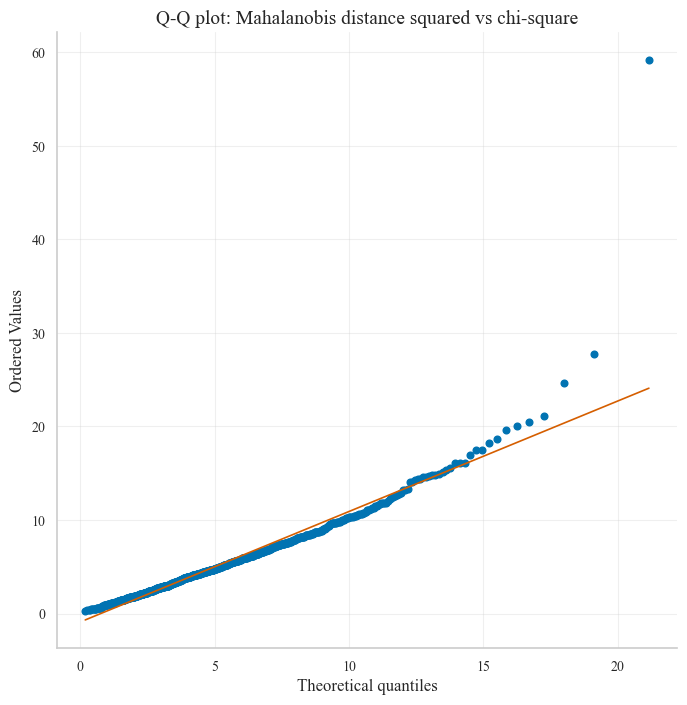

In [7]:
plt.figure(figsize=(8, 8))
probplot(squared_distance, dist=stats.chi2(df=dof), plot=plt)
plt.title('Q-Q plot: Mahalanobis distance squared vs chi-square')
plt.show()

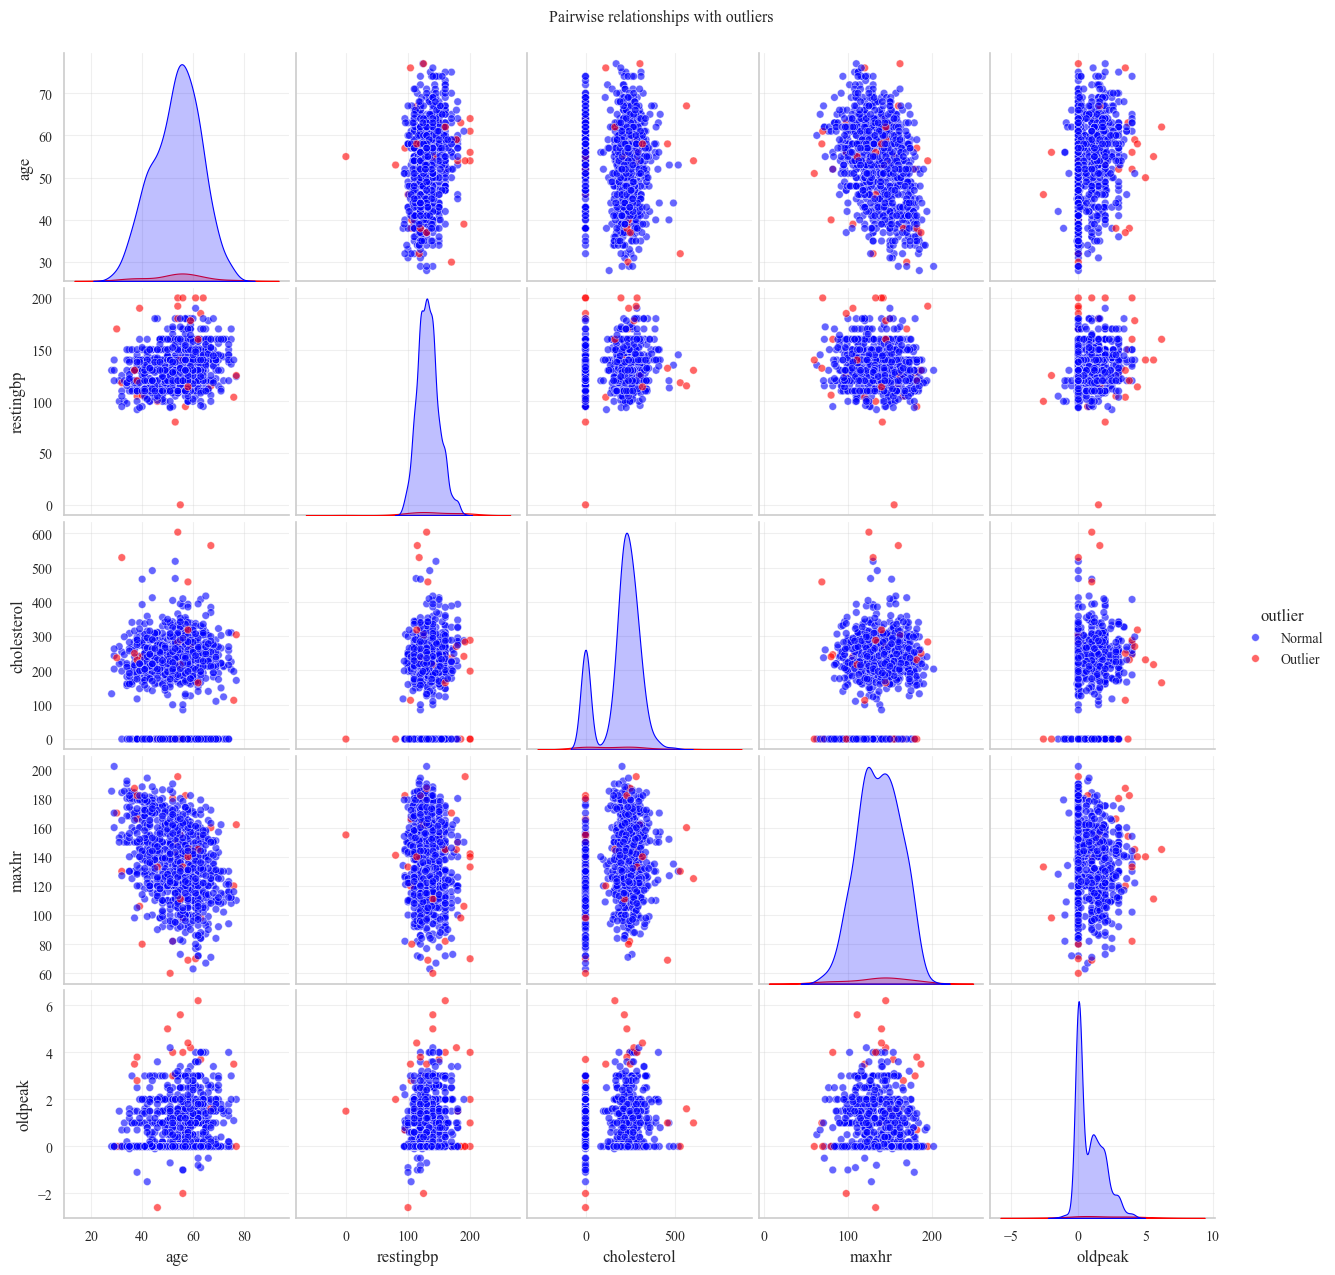

In [8]:
sns.pairplot(data.assign(outlier=data['is_outlier'].map({True: 'Outlier', False: 'Normal'})),
             vars=NUM_COLS, hue='outlier',
             palette={'Normal': 'blue', 'Outlier': 'red'},
             plot_kws={'alpha': 0.6, 's': 30}, diag_kind='kde')
plt.suptitle('Pairwise relationships with outliers', y=1.02)
plt.show()

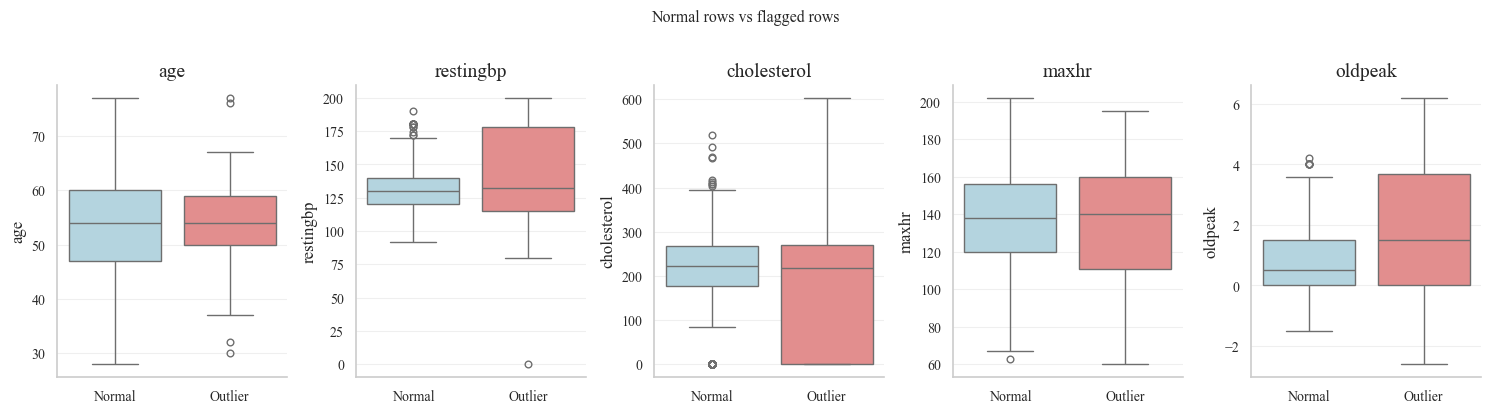

In [9]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(15, 4))
labelled = data.assign(group=data['is_outlier'].map({True: 'Outlier', False: 'Normal'}))

for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=labelled, x='group', y=col, ax=ax,
                hue='group', legend=False,
                palette={'Normal': 'lightblue', 'Outlier': 'lightcoral'})
    ax.set_title(col)
    ax.set_xlabel('')

fig.suptitle('Normal rows vs flagged rows', y=1.02)
plt.tight_layout()
plt.show()